# Analisis Tren dan Pola Musiman Penyewaan Sepeda Berdasarkan Waktu dan Kondisi Hari

**Mata Kuliah:** CAK4XBB3 Visualisasi Data — Midterm Project
**Kelompok 3**

| Nama | NIM |
|---|---|
|Alexandra Yohana Junita S | 103012430049 |
| Jeffry Kurniawan Visnu | 103012300186 |
| Fransisca Anggraeni Hartakaadi | 103012300366 |
| Naufal Raja Pradiptya Pribadi | 103012300235 |
| Godwin Halley Wattimena| 103012580020 |

## Sumber Data
- **Nama dataset:** Bike Sharing Dataset (`day.csv`) — Fanaee-T & Gama (2013)
- **URL:** https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- **Isi:** jumlah penyewaan sepeda Capital Bikeshare (Washington D.C.) per hari, beserta cuaca, musim, status hari kerja/libur, serta jumlah penyewa *casual* dan *registered*
- **Granularitas:** harian, 731 observasi (1 Jan 2011 – 31 Des 2012)

## Pertanyaan Analisis
1. Bagaimana tren jangka panjang penyewaan sepeda selama dua tahun?
2. Apakah ada pola musiman, baik bulanan maupun mingguan?
3. Bagaimana perbedaan perilaku penyewa *registered* (member) dan *casual*?
4. Bagaimana kondisi hari (hari kerja, libur, cuaca) memengaruhi jumlah penyewaan?

## Daftar Isi
1. Load & cleaning data
2. Line plot — penyewaan harian
3. Area plot — akumulasi casual & registered
4. Multiple time series — registered vs casual
5. Seasonal plot — bulanan & hari dalam seminggu (+ calendar heatmap)
6. Analisis tren — moving average 7 & 30 hari, linear & polynomial fit
7. Komponen time series, insight, kesimpulan

## 1. Import Library & Pengaturan Visual

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import calendar

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "font.family": "DejaVu Sans",
})
C_TOTAL, C_CAS, C_REG = "#2E4057", "#F18F01", "#048BA8"
C_MAX, C_MIN = "#2A9D8F", "#E63946"

## 2. Load Data
Upload `day.csv` ke Colab (ikon folder di kiri) sebelum menjalankan. Jika file tidak ada, notebook mencoba mengunduh langsung dari UCI.

In [2]:
import os, io, zipfile, urllib.request
FILE = "day.csv"
URL_ZIP = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
if not os.path.exists(FILE):
    try:
        raw = urllib.request.urlopen(URL_ZIP, timeout=30).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            z.extract("day.csv")
        print("day.csv diunduh dari UCI")
    except Exception as e:
        raise FileNotFoundError("day.csv tidak ditemukan. Upload day.csv ke Colab (ikon folder di kiri) lalu jalankan ulang.") from e
df_raw = pd.read_csv(FILE)
print(df_raw.shape)
df_raw.head()

day.csv diunduh dari UCI
(731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 3. Cleaning & Persiapan Data
Kolom tanggal di-*parse* menjadi `datetime`, dijadikan index, diurutkan kronologis, lalu dicek missing value, duplikat, dan tanggal yang hilang. Kolom `temp` dikembalikan ke °C (nilai asli dinormalisasi dengan pembagi 41).

In [3]:
df = df_raw.copy()
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values("dteday").set_index("dteday")
print("Missing value total :", df.isna().sum().sum())
print("Tanggal duplikat    :", df.index.duplicated().sum())
full_range = pd.date_range(df.index.min(), df.index.max(), freq="D")
print("Tanggal hilang      :", len(full_range.difference(df.index)))
df = df.asfreq("D")
df["temp_c"] = df["temp"] * 41
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju ringan", 4: "Cuaca ekstrem"}
df["season_name"] = df["season"].map(season_map)
df["weather_name"] = df["weathersit"].map(weather_map)
print(f"Periode: {df.index.min().date()} s.d. {df.index.max().date()} | {len(df)} observasi harian")
df[["casual", "registered", "cnt", "temp_c", "weathersit"]].describe().round(1)

Missing value total : 0
Tanggal duplikat    : 0
Tanggal hilang      : 0
Periode: 2011-01-01 s.d. 2012-12-31 | 731 observasi harian


,casual,registered,cnt,temp_c,weathersit
count,731.0,731.0,731.0,731.0,731.0
mean,848.2,3656.2,4504.3,20.3,1.4
std,686.6,1560.3,1937.2,7.5,0.5
min,2.0,20.0,22.0,2.4,1.0
25%,315.5,2497.0,3152.0,13.8,1.0
50%,713.0,3662.0,4548.0,20.4,1.0
75%,1096.0,4776.5,5956.0,26.9,2.0
max,3410.0,6946.0,8714.0,35.3,3.0


**Hasil cleaning:** data sudah bersih  **0 missing value, 0 tanggal duplikat, 0 tanggal hilang** dari 731 hari berurutan.

Variabel utama:
- `cnt` — total penyewaan per hari (= casual + registered)
- `casual` — penyewa non-member
- `registered` — penyewa member terdaftar
- `temp_c`, `weathersit`, `season`, `workingday`, `holiday` — konteks kondisi hari

## 4. Visualisasi 1 — Line Plot: Penyewaan Sepeda per Hari

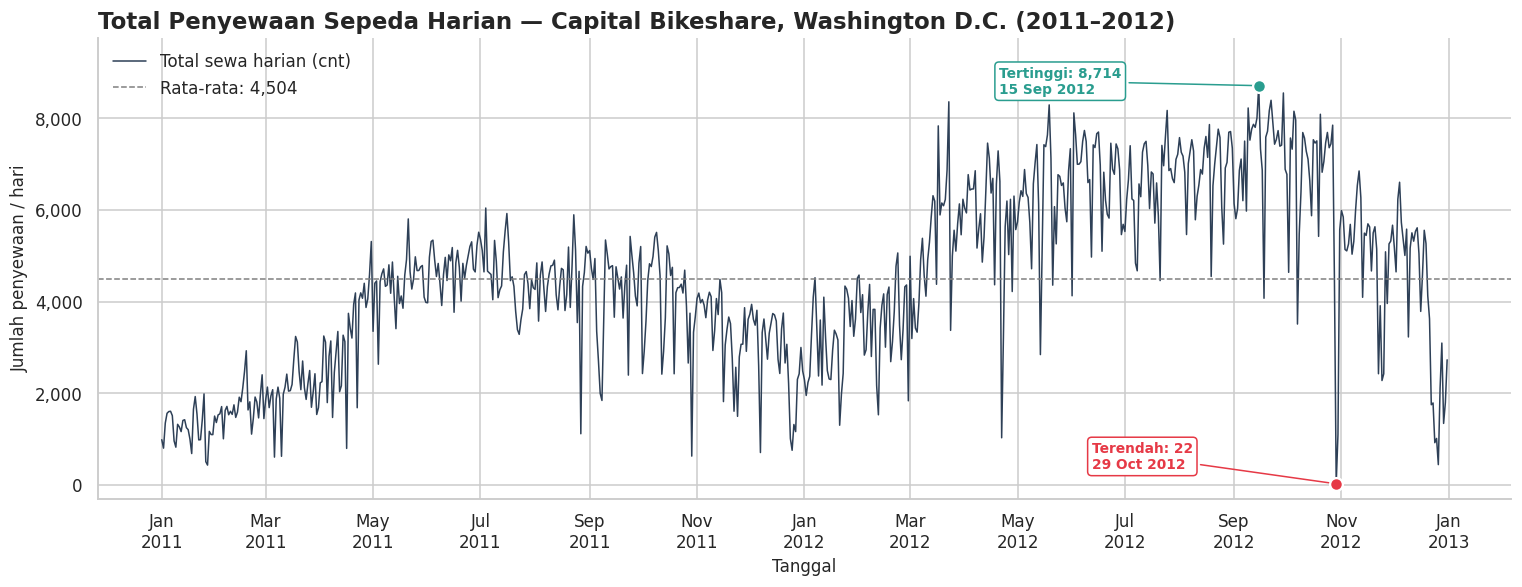

In [4]:
def mark_extremes(ax, series, fmt="{:,.0f}", offset_max=(15, 18), offset_min=(15, -30)):
    i_max, i_min = series.idxmax(), series.idxmin()
    for idx, color, off, lab in [(i_max, C_MAX, offset_max, "Tertinggi"), (i_min, C_MIN, offset_min, "Terendah")]:
        val = series.loc[idx]
        ax.scatter(idx, val, s=70, color=color, zorder=5, edgecolor="white", linewidth=1.5)
        ax.annotate(f"{lab}: {fmt.format(val)}\n{idx:%d %b %Y}", xy=(idx, val), xytext=off,
                    textcoords="offset points", fontsize=9, fontweight="bold", color=color,
                    arrowprops=dict(arrowstyle="-", color=color, lw=1),
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, lw=1))
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(df.index, df["cnt"], color=C_TOTAL, lw=1, label="Total sewa harian (cnt)")
ax.axhline(df["cnt"].mean(), color="grey", ls="--", lw=1, label=f"Rata-rata: {df['cnt'].mean():,.0f}")
mark_extremes(ax, df["cnt"], offset_max=(-170, -5), offset_min=(-160, 10))
ax.set_ylim(-300, df["cnt"].max() * 1.12)
ax.set_title("Total Penyewaan Sepeda Harian — Capital Bikeshare, Washington D.C. (2011–2012)", loc="left")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Jumlah penyewaan / hari")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

**Interpretasi:**

Grafik garis memperlihatkan bahwa jumlah penyewaan sepeda harian meningkat cukup jelas selama dua tahun. Pada awal 2011 penyewaan masih berada di kisaran 1.000 sewa per hari, lalu naik hingga sekitar 7.000–8.000 sewa per hari pada pertengahan 2012. Garis putus-putus menunjukkan rata-rata keseluruhan sebesar 4.504 sewa per hari. Sekitar 72% hari pada 2011 berada di bawah rata-rata ini, sedangkan pada 2012 hanya sekitar 26% hari yang berada di bawahnya.

Selain naik, garis membentuk pola gelombang yang berulang. Penyewaan meningkat saat memasuki musim semi dan musim panas, kemudian menurun menjelang akhir tahun. Pola yang sama muncul pada 2011 maupun 2012, sehingga dapat disimpulkan bahwa jumlah penyewaan dipengaruhi oleh musim.

Titik tertinggi terjadi pada Sabtu, 15 September 2012 dengan 8.714 sewa. Titik terendah terjadi pada 29 Oktober 2012 dengan hanya 22 sewa. Penurunan sedrastis ini tidak sesuai dengan pola di sekitarnya sehingga dapat dianggap sebagai outlier. Tanggal tersebut bertepatan dengan Badai Sandy yang melanda Washington D.C. (informasi ini berasal dari konteks luar, bukan dari kolom dataset).

## 5. Visualisasi 2 — Area Plot: Akumulasi Penyewa Casual & Registered

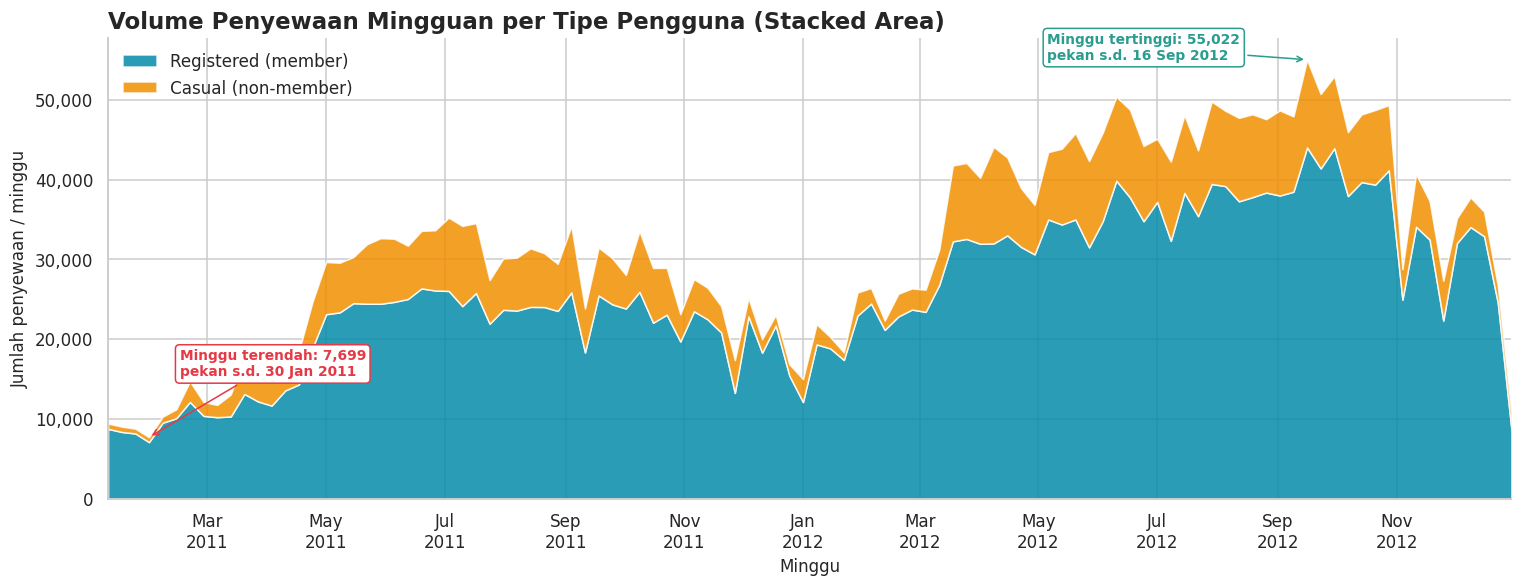

Porsi casual: 18.8% | registered: 81.2%


In [5]:
weekly = df[["casual", "registered"]].resample("W").sum().iloc[1:-1]  # buang minggu pertama & terakhir yang tidak penuh 7 hari
weekly_total = weekly.sum(axis=1)
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.stackplot(weekly.index, weekly["registered"], weekly["casual"], labels=["Registered (member)", "Casual (non-member)"],
             colors=[C_REG, C_CAS], alpha=0.85)
w_max, w_min = weekly_total.idxmax(), weekly_total.idxmin()
for idx, color, lab, off in [(w_max, C_MAX, "Minggu tertinggi", (-170, 0)), (w_min, C_MIN, "Minggu terendah", (20, 40))]:
    ax.annotate(f"{lab}: {weekly_total[idx]:,.0f}\npekan s.d. {idx:%d %b %Y}", xy=(idx, weekly_total[idx]), xytext=off,
                textcoords="offset points", fontsize=9, fontweight="bold", color=color,
                arrowprops=dict(arrowstyle="->", color=color),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color))
ax.set_title("Volume Penyewaan Mingguan per Tipe Pengguna (Stacked Area)", loc="left")
ax.set_xlabel("Minggu"); ax.set_ylabel("Jumlah penyewaan / minggu")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.legend(loc="upper left"); ax.set_xlim(weekly.index.min(), weekly.index.max())
plt.tight_layout(); plt.show()
share = df["casual"].sum() / df["cnt"].sum() * 100
print(f"Porsi casual: {share:.1f}% | registered: {100-share:.1f}%")

**Interpretasi:**

Dari grafik area bertumpuk terlihat bahwa sebagian besar volume penyewaan berasal dari pengguna registered (biru), yaitu 81,2% dari total penyewaan. Pengguna casual (oranye) hanya menyumbang 18,8%. Artinya, layanan ini terutama digunakan oleh member yang memakai sepeda secara rutin.

Ketebalan lapisan casual berubah mengikuti musim. Pada musim panas lapisan oranye terlihat tebal, sedangkan pada musim dingin lapisan tersebut hampir tidak terlihat. Hal ini menunjukkan bahwa pengguna casual lebih terpengaruh oleh musim dibandingkan pengguna registered, yang lapisannya tetap tebal sepanjang tahun.

Volume mingguan tertinggi tercatat pada pekan yang berakhir 16 September 2012 dengan 55.022 sewa, sedangkan volume terendah terjadi pada pekan yang berakhir 30 Januari 2011 dengan 7.699 sewa. Selisih keduanya lebih dari tujuh kali lipat, yang menggambarkan besarnya pertumbuhan sekaligus pengaruh musim. Minggu pertama dan terakhir tidak diikutkan karena tidak berisi tujuh hari penuh.

## 6. Visualisasi 3 — Multiple Time Series: Registered vs Casual
Direct labeling di ujung garis digunakan sebagai pengganti legend agar tidak menjadi *spaghetti chart*.

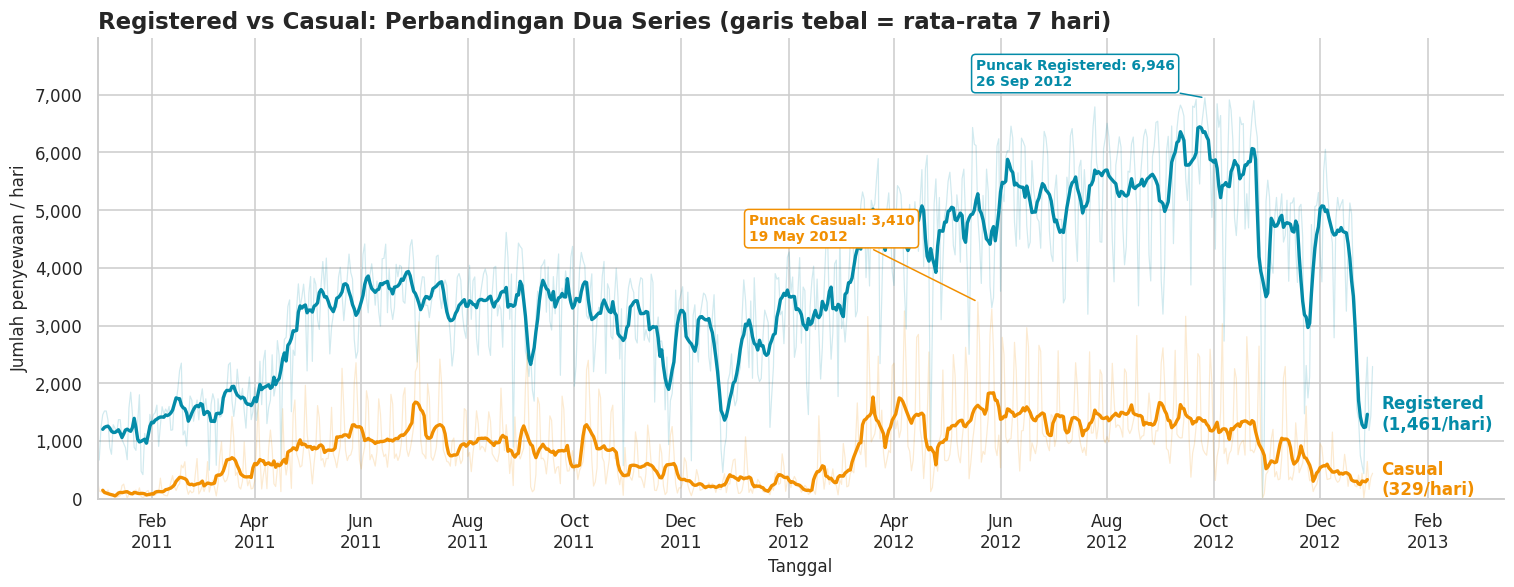

In [6]:
roll = df[["casual", "registered"]].rolling(7, center=True).mean()
fig, ax = plt.subplots(figsize=(14, 5.5))
for col, color, name in [("registered", C_REG, "Registered"), ("casual", C_CAS, "Casual")]:
    ax.plot(df.index, df[col], color=color, alpha=0.18, lw=0.8)
    ax.plot(roll.index, roll[col], color=color, lw=2.2)
    last_idx = roll[col].last_valid_index()
    ax.text(last_idx + pd.Timedelta(days=8), roll[col][last_idx], f"{name}\n({roll[col][last_idx]:,.0f}/hari)",
            color=color, fontsize=11, fontweight="bold", va="center")
    p = df[col].idxmax()
    ax.annotate(f"Puncak {name}: {df[col][p]:,.0f}\n{p:%d %b %Y}", xy=(p, df[col][p]), xytext=(-150, 8 if col=='registered' else 40),
                textcoords="offset points", fontsize=9, color=color, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=color),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color))
ax.set_xlim(df.index.min(), df.index.max() + pd.Timedelta(days=75)); ax.set_ylim(0, df["registered"].max() * 1.15)
ax.set_title("Registered vs Casual: Perbandingan Dua Series (garis tebal = rata-rata 7 hari)", loc="left")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Jumlah penyewaan / hari")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
plt.tight_layout(); plt.show()

**Interpretasi:**

Grafik ini membandingkan dua kelompok penyewa pada sumbu waktu yang sama. Kedua garis naik dan turun pada periode yang hampir bersamaan, sehingga keduanya mengikuti pola musim yang serupa. Namun, jumlahnya berbeda jauh. Pengguna registered umumnya berada di kisaran 3.000–6.500 sewa per hari, sedangkan pengguna casual hanya sekitar 200–1.800 sewa per hari.

Puncak kedua kelompok jatuh pada jenis hari yang berbeda. Puncak registered terjadi pada Rabu, 26 September 2012 dengan 6.946 sewa, yaitu pada hari kerja. Puncak casual terjadi pada Sabtu, 19 Mei 2012 dengan 3.410 sewa, yaitu pada akhir pekan. Perbedaan ini mengindikasikan bahwa pengguna registered cenderung memakai sepeda untuk perjalanan rutin seperti berangkat kerja, sedangkan pengguna casual lebih banyak memakainya untuk rekreasi.

Garis tipis casual juga terlihat bergerigi dengan pola yang teratur. Gerigi ini merupakan lonjakan yang berulang setiap akhir pekan dan dibahas lebih lanjut pada seasonal plot mingguan.

## 7. Visualisasi 4 — Seasonal Plot
### 7a. Pola Bulanan: 2011 vs 2012

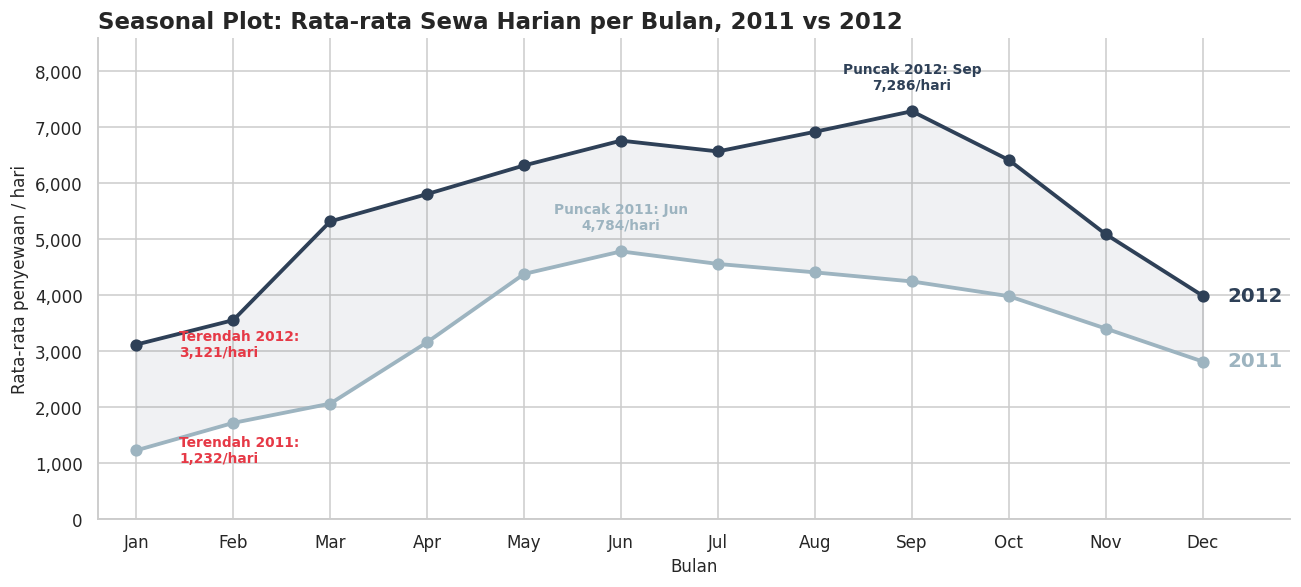

Pertumbuhan 2012 vs 2011 per bulan (%):
Jan    153.3
Feb    106.5
Mar    157.4
Apr     83.6
May     44.2
Jun     41.3
Jul     44.1
Aug     56.9
Sep     71.5
Oct     61.0
Nov     49.4
Dec     41.7


In [7]:
monthly = df["cnt"].groupby([df.index.year, df.index.month]).mean().unstack(0)
months = [calendar.month_abbr[m] for m in monthly.index]
fig, ax = plt.subplots(figsize=(12, 5.5))
for yr, color in [(2011, "#9DB4C0"), (2012, C_TOTAL)]:
    ax.plot(months, monthly[yr], marker="o", lw=2.5, color=color, ms=7)
    ax.text(11.25, monthly[yr].iloc[-1], str(yr), color=color, fontsize=13, fontweight="bold", va="center")
    m_max = monthly[yr].idxmax()
    ax.annotate(f"Puncak {yr}: {calendar.month_abbr[m_max]}\n{monthly[yr].max():,.0f}/hari", xy=(m_max-1, monthly[yr].max()),
                xytext=(0, 14), textcoords="offset points", ha="center", fontsize=9, fontweight="bold", color=color)
    m_min = monthly[yr].idxmin()
    ax.annotate(f"Terendah {yr}:\n{monthly[yr].min():,.0f}/hari", xy=(m_min-1, monthly[yr].min()),
                xytext=(28, -8), textcoords="offset points", fontsize=9, fontweight="bold", color=C_MIN)
ax.fill_between(range(12), monthly[2011], monthly[2012], color=C_TOTAL, alpha=0.07)
ax.set_xlim(-0.4, 11.9); ax.set_ylim(0, monthly.max().max() * 1.18)
ax.set_title("Seasonal Plot: Rata-rata Sewa Harian per Bulan, 2011 vs 2012", loc="left")
ax.set_xlabel("Bulan"); ax.set_ylabel("Rata-rata penyewaan / hari")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); plt.show()
growth = (monthly[2012] / monthly[2011] - 1) * 100
print("Pertumbuhan 2012 vs 2011 per bulan (%):"); print(growth.round(1).set_axis(months).to_string())

**Interpretasi:**

Seasonal plot menunjukkan bahwa kurva 2011 dan 2012 memiliki bentuk yang mirip, yaitu seperti bukit: rendah di awal tahun, naik hingga pertengahan tahun, lalu turun kembali menjelang Desember. Karena bentuk ini berulang di dua tahun yang berbeda, data ini memiliki pola musiman tahunan.

Januari menjadi bulan dengan rata-rata terendah di kedua tahun, yaitu 1.232 sewa per hari pada 2011 dan 3.121 sewa per hari pada 2012. Bulan puncaknya berbeda. Pada 2011 puncak terjadi di bulan Juni (4.784 sewa per hari), sedangkan pada 2012 puncak bergeser ke bulan September (7.286 sewa per hari).

Kurva 2012 selalu berada di atas kurva 2011 di semua bulan, yang berarti terjadi pertumbuhan sepanjang tahun. Dari tabel pertumbuhan di bawah grafik terlihat bahwa kenaikan terbesar justru terjadi pada bulan-bulan dingin, yaitu Januari (+153%) dan Maret (+157%), sedangkan Juni hanya naik 41%. Hal ini menunjukkan bahwa sepeda semakin banyak dipakai bahkan pada bulan yang sebelumnya sepi.

### 7b. Pola Mingguan: Hari dalam Seminggu

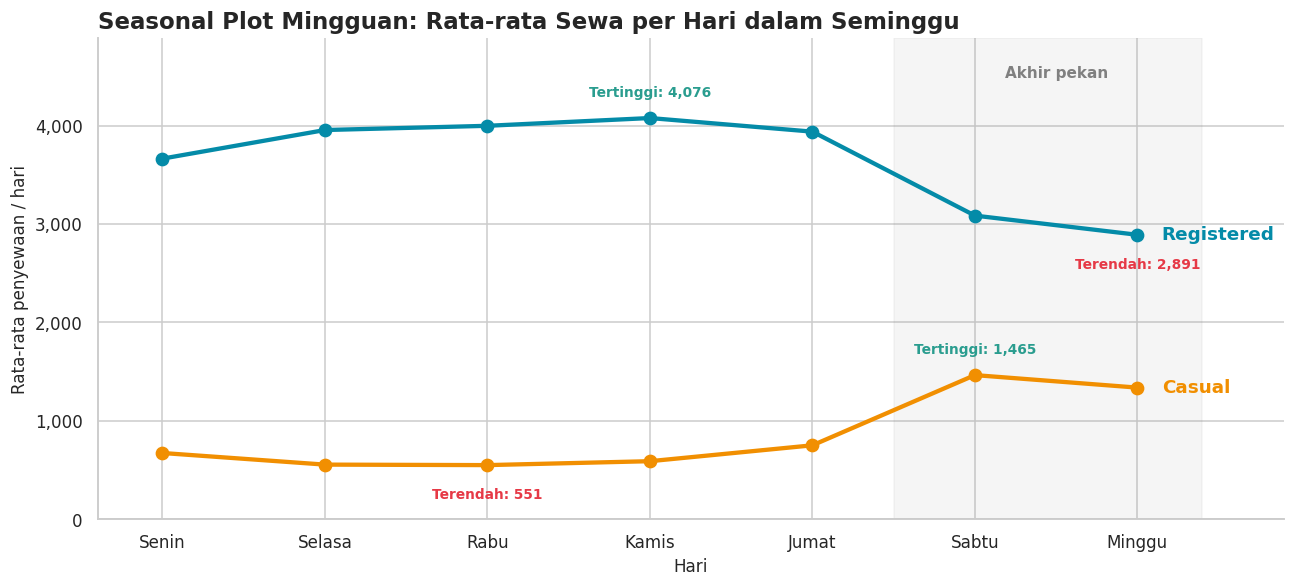

Casual Sabtu vs Rabu: 2.7x lipat
                   casual  registered
Libur/Akhir pekan  1371.0      2959.0
Hari kerja          607.0      3978.0


In [8]:
# Seasonal plot mingguan: pola rata-rata per hari dalam seminggu
dow_order = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
dow_mean = df.groupby(df.index.dayofweek)[["casual", "registered"]].mean()
dow_mean.index = dow_order

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.axvspan(4.5, 6.4, color="grey", alpha=0.08)
ax.text(5.5, dow_mean.values.max() * 1.1, "Akhir pekan", ha="center", color="grey", fontsize=10, fontweight="bold")
for col, color, name in [("registered", C_REG, "Registered"), ("casual", C_CAS, "Casual")]:
    ax.plot(dow_order, dow_mean[col], marker="o", lw=2.8, ms=8, color=color)
    ax.text(6.15, dow_mean[col].iloc[-1], name, color=color, fontsize=12, fontweight="bold", va="center")
    for idx, c, lab, dy in [(dow_mean[col].idxmax(), C_MAX, "Tertinggi", 14), (dow_mean[col].idxmin(), C_MIN, "Terendah", -22)]:
        ax.annotate(f"{lab}: {dow_mean[col][idx]:,.0f}", xy=(dow_order.index(idx), dow_mean[col][idx]),
                    xytext=(0, dy), textcoords="offset points", ha="center", fontsize=9, fontweight="bold", color=c)
ax.set_xlim(-0.4, 6.9); ax.set_ylim(0, dow_mean.values.max() * 1.2)
ax.set_title("Seasonal Plot Mingguan: Rata-rata Sewa per Hari dalam Seminggu", loc="left")
ax.set_xlabel("Hari"); ax.set_ylabel("Rata-rata penyewaan / hari")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); plt.show()

ratio = dow_mean.loc["Sabtu", "casual"] / dow_mean.loc["Rabu", "casual"]
print(f"Casual Sabtu vs Rabu: {ratio:.1f}x lipat")
print(df.groupby("workingday")[["casual", "registered"]].mean().round(0).set_axis(["Libur/Akhir pekan", "Hari kerja"]))

**Interpretasi:**

Grafik ini memperlihatkan pola yang berlawanan antara kedua kelompok penyewa. Rata-rata penyewaan registered tinggi pada hari Senin sampai Jumat, dengan nilai tertinggi pada hari Kamis (4.076 sewa), lalu turun pada akhir pekan hingga mencapai titik terendah pada hari Minggu (2.891 sewa). Pola ini sesuai dengan kebiasaan perjalanan ke tempat kerja atau sekolah.

Sebaliknya, rata-rata penyewaan casual rendah pada hari kerja, dengan nilai terendah pada hari Rabu (551 sewa), lalu melonjak pada akhir pekan hingga tertinggi pada hari Sabtu (1.465 sewa). Jumlah pada hari Sabtu sekitar 2,7 kali lipat dibandingkan hari Rabu. Tabel di bawah grafik menguatkan pola ini. Pada hari kerja, rata-rata casual hanya 607 dan registered 3.978, sedangkan pada hari libur atau akhir pekan casual naik menjadi 1.371 dan registered turun menjadi 2.959.

Karena kenaikan satu kelompok diimbangi oleh penurunan kelompok lainnya, total penyewaan harian relatif stabil sepanjang minggu, yaitu berkisar antara 4.229 dan 4.690 sewa per hari.

### 7c. Calendar Heatmap
Menampilkan kepadatan penyewaan setiap hari sepanjang dua tahun.

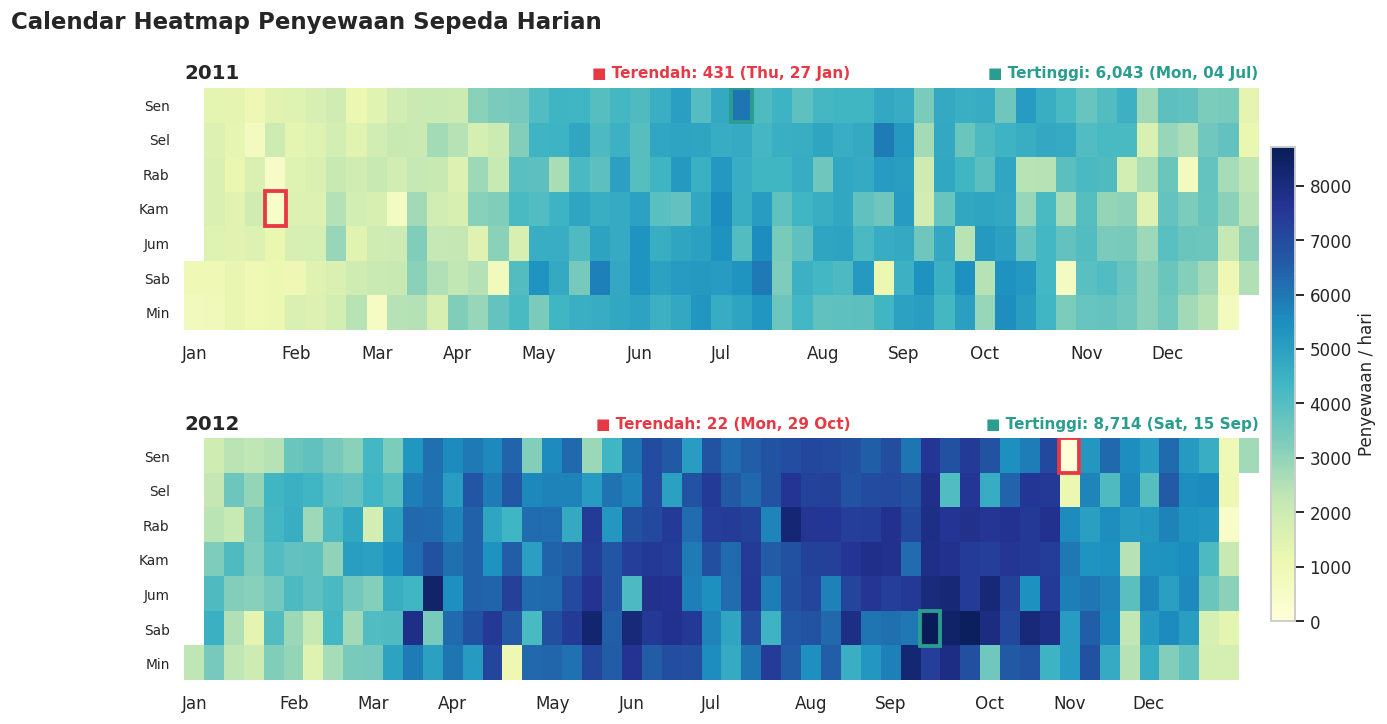

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7), gridspec_kw={"hspace": 0.45})
vmax = df["cnt"].max()
for ax, yr in zip(axes, [2011, 2012]):
    d = df.loc[str(yr), ["cnt"]].copy()
    d["dow"] = d.index.dayofweek
    first_dow = pd.Timestamp(f"{yr}-01-01").dayofweek
    d["week"] = (d.index.dayofyear - 1 + first_dow) // 7
    grid = d.pivot(index="dow", columns="week", values="cnt")
    im = ax.imshow(grid, cmap="YlGnBu", aspect="auto", vmin=0, vmax=vmax)
    ax.set_yticks(range(7)); ax.set_yticklabels(["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"], fontsize=9)
    starts = [pd.Timestamp(f"{yr}-{m:02d}-01") for m in range(1, 13)]
    ax.set_xticks([(s.dayofyear - 1 + first_dow) // 7 for s in starts]); ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)])
    ax.set_title(str(yr), loc="left", fontsize=13); ax.grid(False)
    i_max, i_min = d["cnt"].idxmax(), d["cnt"].idxmin()
    for idx, color in [(i_max, C_MAX), (i_min, C_MIN)]:
        ax.add_patch(plt.Rectangle((d.loc[idx, "week"] - 0.5, d.loc[idx, "dow"] - 0.5), 1, 1, fill=False, ec=color, lw=2.5))
    ax.text(1, 1.04, f"■ Tertinggi: {d.loc[i_max,'cnt']:,} ({i_max:%a, %d %b})", transform=ax.transAxes,
            ha="right", color=C_MAX, fontsize=10, fontweight="bold")
    ax.text(0.62, 1.04, f"■ Terendah: {d.loc[i_min,'cnt']:,} ({i_min:%a, %d %b})", transform=ax.transAxes,
            ha="right", color=C_MIN, fontsize=10, fontweight="bold")
for ax in axes:
    for s in ax.spines.values(): s.set_visible(False)
cbar = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.01); cbar.set_label("Penyewaan / hari")
fig.suptitle("Calendar Heatmap Penyewaan Sepeda Harian", x=0.02, ha="left", fontsize=15, fontweight="bold")
plt.show()

**Interpretasi:**

Pada calendar heatmap, setiap kotak mewakili satu hari, dan warna yang lebih gelap berarti penyewaan lebih banyak. Warna gelap paling banyak terkumpul pada Mei hingga Oktober 2012, sedangkan Januari dan Februari 2011 tampak paling pucat. Pola ini sejalan dengan temuan sebelumnya bahwa penyewaan meningkat dari tahun ke tahun dan lebih ramai pada pertengahan tahun.

Pada 2011, hari dengan penyewaan tertinggi adalah Senin, 4 Juli dengan 6.043 sewa, yang bertepatan dengan Hari Kemerdekaan Amerika Serikat. Hari terendah pada tahun tersebut adalah Kamis, 27 Januari dengan 431 sewa. Pada 2012, hari tertinggi adalah Sabtu, 15 September dengan 8.714 sewa, dan hari terendah adalah Senin, 29 Oktober dengan 22 sewa.

Beberapa kotak berwarna pucat juga terlihat menyendiri di tengah periode yang ramai. Kotak-kotak ini menandai hari ketika penyewaan turun secara tiba-tiba, yang umumnya terjadi karena cuaca buruk seperti hujan atau badai.

## 8. Analisis Tren
### 8a. Moving Average 7 Hari vs 30 Hari

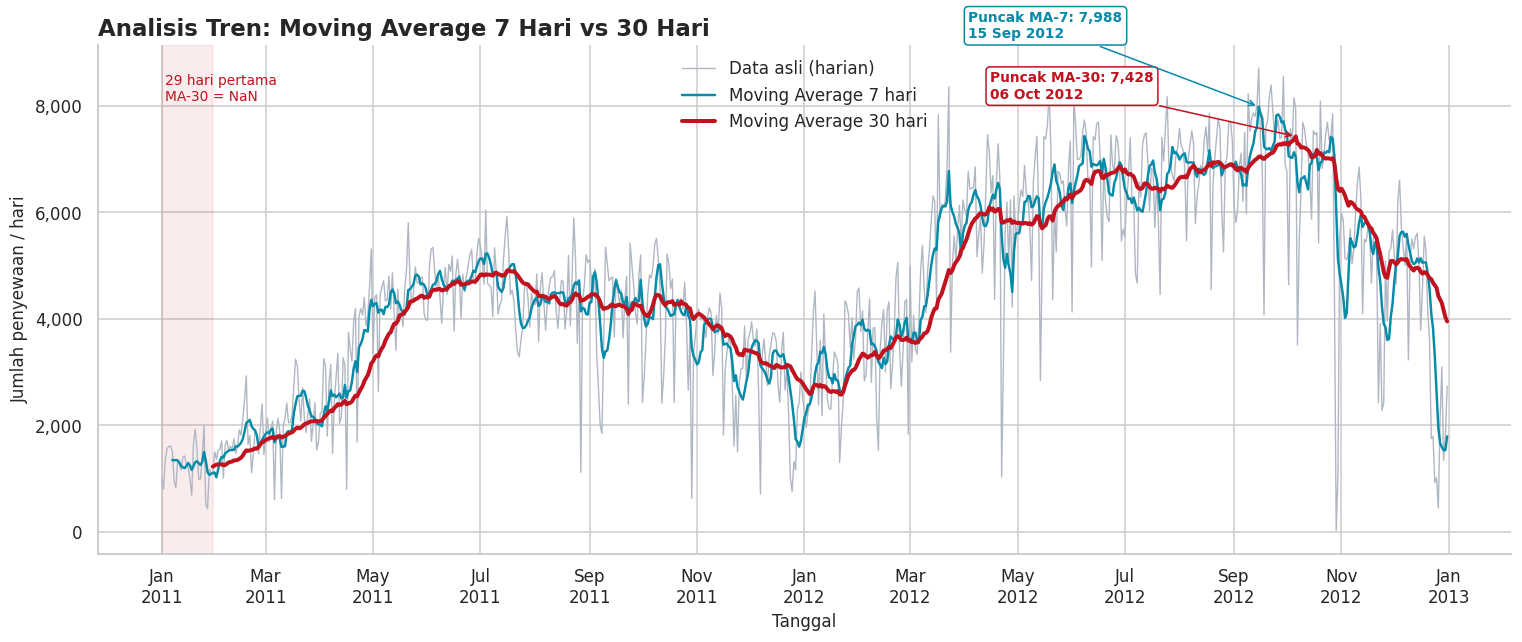

NaN MA-7 : 6 hari | NaN MA-30: 29 hari
Std perubahan harian -> asli: 1,065 | MA-7: 192 | MA-30: 52


In [10]:
ma7 = df["cnt"].rolling(window=7).mean()
ma30 = df["cnt"].rolling(window=30).mean()
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df.index, df["cnt"], color="#B0B7C3", lw=0.9, label="Data asli (harian)")
ax.plot(ma7.index, ma7, color=C_REG, lw=1.6, label="Moving Average 7 hari")
ax.plot(ma30.index, ma30, color="#C1121F", lw=2.6, label="Moving Average 30 hari")
ax.axvspan(df.index[0], df.index[29], color="#C1121F", alpha=0.08)
ax.text(df.index[2], df["cnt"].max() * 0.93, "29 hari pertama\nMA-30 = NaN", fontsize=9, color="#C1121F")
for s, c, lab, off in [(ma30, "#C1121F", "Puncak MA-30", (-200, 25)), (ma7, C_REG, "Puncak MA-7", (-190, 45))]:
    i = s.idxmax()
    ax.annotate(f"{lab}: {s[i]:,.0f}\n{i:%d %b %Y}", xy=(i, s[i]), xytext=off, textcoords="offset points",
                fontsize=9, fontweight="bold", color=c, arrowprops=dict(arrowstyle="->", color=c),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=c))
ax.set_title("Analisis Tren: Moving Average 7 Hari vs 30 Hari", loc="left")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Jumlah penyewaan / hari")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.legend(loc="upper center"); plt.tight_layout(); plt.show()
print(f"NaN MA-7 : {ma7.isna().sum()} hari | NaN MA-30: {ma30.isna().sum()} hari")
print(f"Std perubahan harian -> asli: {df['cnt'].diff().std():,.0f} | MA-7: {ma7.diff().std():,.0f} | MA-30: {ma30.diff().std():,.0f}")

**Interpretasi:**

Grafik ini membandingkan data asli dengan dua garis moving average. Data asli (abu-abu) naik turun cukup tajam dari hari ke hari, sehingga arah tren sulit dibaca. Moving average 7 hari (biru) sudah meredam fluktuasi harian, termasuk perbedaan antara hari kerja dan akhir pekan, tetapi masih ikut turun tajam saat terjadi kejadian jangka pendek seperti Badai Sandy pada akhir Oktober 2012. Moving average 30 hari (merah) jauh lebih halus dan memperlihatkan bentuk besar tren musiman, yaitu naik pada pertengahan 2011, turun di akhir 2011, lalu naik lebih tinggi pada 2012.

Tingkat kehalusan ini juga terlihat dari output di bawah grafik. Standar deviasi perubahan harian turun dari 1.065 pada data asli menjadi 192 pada MA-7 dan 52 pada MA-30.

Namun, window yang lebih besar memiliki dua kekurangan. Pertama, semakin banyak data di awal periode yang hilang. MA-7 tidak memiliki nilai pada 6 hari pertama, sedangkan MA-30 tidak memiliki nilai pada 29 hari pertama (area merah muda pada grafik). Kedua, MA-30 lebih lambat merespons perubahan. Puncak MA-7 terjadi pada 15 September 2012 dengan nilai 7.988, sedangkan puncak MA-30 baru muncul pada 6 Oktober 2012 dengan nilai 7.428, atau terlambat sekitar tiga minggu.

Berdasarkan hal tersebut, MA-30 lebih cocok untuk membaca tren musiman jangka panjang, sedangkan MA-7 lebih cocok untuk memantau perubahan dari minggu ke minggu.

### 8b. Fitting Model: Linear vs Polynomial (numpy.polyfit)

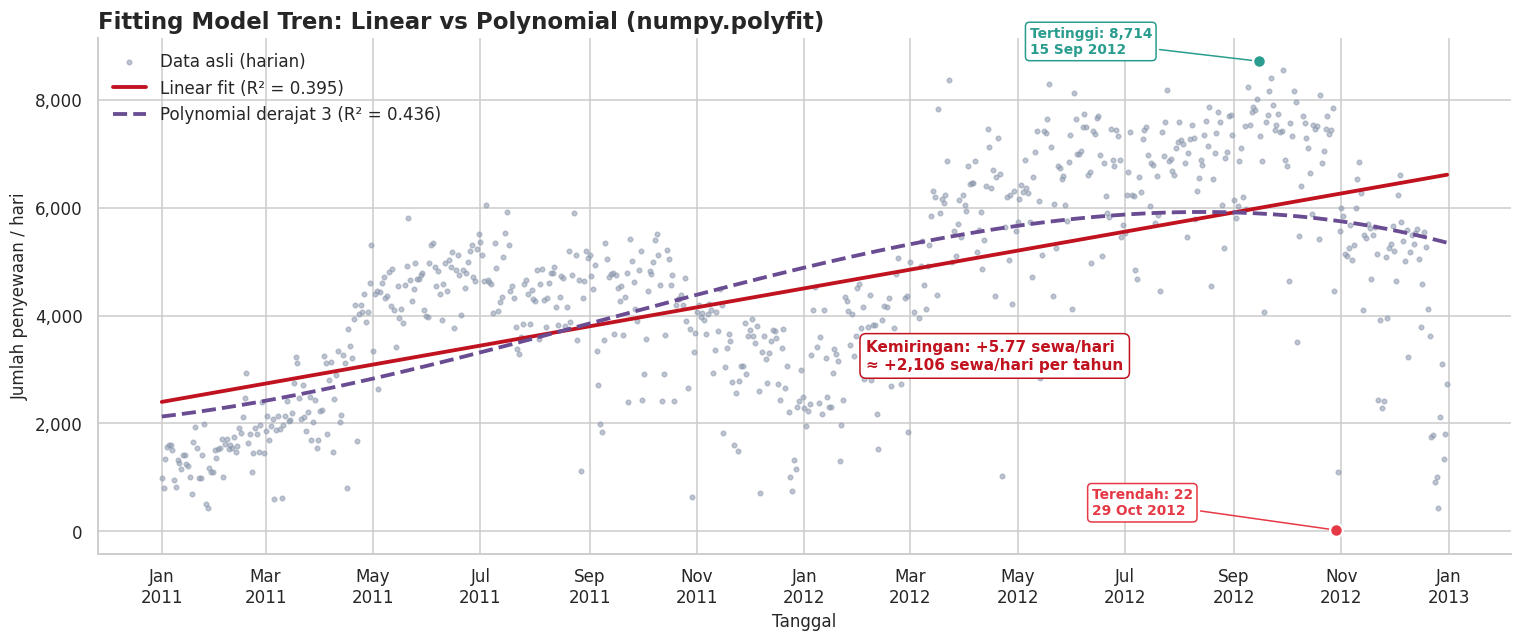

Linear: cnt = 5.769·t + 2,398.7
Prediksi tren awal (1 Jan 2011): 2,399 | akhir (31 Des 2012): 6,610


In [11]:
x = np.arange(len(df)); y = df["cnt"].values
def r2(y, yhat): return 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum()
coef1 = np.polyfit(x, y, 1); fit1 = np.polyval(coef1, x)
coef3 = np.polyfit(x, y, 3); fit3 = np.polyval(coef3, x)
fig, ax = plt.subplots(figsize=(14, 6))
ax.scatter(df.index, y, s=9, color="#8D99AE", alpha=0.55, label="Data asli (harian)")
ax.plot(df.index, fit1, color="#C1121F", lw=2.5, label=f"Linear fit (R² = {r2(y, fit1):.3f})")
ax.plot(df.index, fit3, color="#6A4C93", lw=2.5, ls="--", label=f"Polynomial derajat 3 (R² = {r2(y, fit3):.3f})")
ax.text(df.index[400], fit1[400] - 1700, f"Kemiringan: +{coef1[0]:.2f} sewa/hari\n≈ +{coef1[0]*365:,.0f} sewa/hari per tahun",
        fontsize=10, color="#C1121F", fontweight="bold", bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#C1121F"))
mark_extremes(ax, df["cnt"], offset_max=(-150, 5), offset_min=(-160, 10))
ax.set_title("Fitting Model Tren: Linear vs Polynomial (numpy.polyfit)", loc="left")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Jumlah penyewaan / hari")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()
print(f"Linear: cnt = {coef1[0]:.3f}·t + {coef1[1]:,.1f}")
print(f"Prediksi tren awal (1 Jan 2011): {fit1[0]:,.0f} | akhir (31 Des 2012): {fit1[-1]:,.0f}")

**Interpretasi:**

Garis linear menunjukkan bahwa secara umum penyewaan naik sekitar 5,77 sewa setiap hari, atau sekitar 2.106 sewa per hari dalam satu tahun. Nilai tren pada awal 2011 sekitar 2.399 sewa per hari dan meningkat menjadi sekitar 6.610 sewa per hari pada akhir 2012.

Nilai R² model linear hanya 0,395, artinya garis lurus hanya mampu menjelaskan sekitar 40% variasi data. Hal ini bukan berarti trennya lemah, melainkan karena sebagian besar variasi berasal dari pola musiman yang naik turun dan tidak dapat ditangkap oleh garis lurus. Hal ini terlihat dari banyaknya titik data yang berada jauh di atas garis pada pertengahan tahun dan jauh di bawah garis pada akhir tahun.

Model polynomial derajat 3 sedikit lebih baik dengan R² sebesar 0,436. Kurvanya melengkung dan mulai mendatar, lalu menurun pada akhir 2012, yang menunjukkan bahwa laju pertumbuhan mulai melambat. Meski begitu, penurunan di ujung kurva juga dipengaruhi oleh musim dingin di akhir periode data. Dari kedua model ini dapat disimpulkan bahwa data merupakan gabungan antara tren naik dan pola musiman tahunan.

## 9. Statistik Pendukung: Pengaruh Kondisi Hari

In [12]:
print("Rata-rata per hari dalam seminggu:")
dow = df.groupby(df.index.dayofweek)[["casual", "registered", "cnt"]].mean().round(0)
dow.index = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]; print(dow, "\n")
print("Rata-rata per kondisi cuaca:"); print(df.groupby("weather_name")["cnt"].agg(["mean", "count"]).round(0), "\n")
print("Rata-rata per musim:"); print(df.groupby("season_name")["cnt"].mean().round(0), "\n")
print("Korelasi suhu (°C) vs cnt:", round(df["temp_c"].corr(df["cnt"]), 3), "\n")
print("5 hari dengan sewa terendah:")
print(df.nsmallest(5, "cnt")[["cnt", "weather_name", "holiday", "temp_c"]].round(1))

print("\nRata-rata hari libur vs bukan libur:")
print(df.groupby("holiday")["cnt"].mean().round(0).set_axis(["Bukan libur", "Hari libur"]))

yearly = df.groupby(df.index.year)["cnt"].agg(["sum", "mean"]).round(0)
print("\nTotal & rata-rata per tahun:"); print(yearly)
print(f"Pertumbuhan total: {(yearly['sum'][2012] / yearly['sum'][2011] - 1) * 100:.1f}%")

print("\nHari ketika casual > registered:")
print(df.loc[df["casual"] > df["registered"], ["casual", "registered", "holiday", "workingday"]])

Rata-rata per hari dalam seminggu:
        casual  registered     cnt
Senin    674.0      3664.0  4338.0
Selasa   556.0      3954.0  4511.0
Rabu     551.0      3997.0  4549.0
Kamis    591.0      4076.0  4667.0
Jumat    752.0      3938.0  4690.0
Sabtu   1465.0      3085.0  4551.0
Minggu  1338.0      2891.0  4229.0 

Rata-rata per kondisi cuaca:
                      mean  count
weather_name                     
Berkabut/Berawan    4036.0    247
Cerah               4877.0    463
Hujan/Salju ringan  1803.0     21 

Rata-rata per musim:
season_name
Fall      5644.0
Spring    2604.0
Summer    4992.0
Winter    4728.0
Name: cnt, dtype: float64 

Korelasi suhu (°C) vs cnt: 0.627 

5 hari dengan sewa terendah:
            cnt        weather_name  holiday  temp_c
dteday                                              
2012-10-29   22  Hujan/Salju ringan        0    18.0
2011-01-27  431               Cerah        0     8.0
2012-12-26  441  Hujan/Salju ringan        0    10.0
2011-01-26  506  Hujan/S

## 10. Identifikasi Komponen Time Series

| Komponen | Teramati? | Bukti |
|---|---|---|
| **Trend** | ✅ Naik | Linear fit +5,77 sewa/hari (8b); kurva 2012 selalu di atas 2011 (7a); total naik dari 1.243.103 (2011) ke 2.049.576 (2012), **+64,9%** |
| **Seasonality** | ✅ Tahunan & mingguan | *Tahunan:* pola "bukit" berulang, rendah Januari–tinggi pertengahan tahun (7a, MA-30). *Mingguan:* casual melonjak Sabtu–Minggu, registered tinggi Senin–Jumat (7b) |
| **Cyclic** | ⚠️ Belum dapat dipastikan | Data hanya 2 tahun, sehingga fluktuasi jangka panjang non-periodik tidak bisa dibedakan dari tren. Pelambatan akhir 2012 (polynomial, 8b) bisa jadi awal siklus, tetapi butuh data lebih panjang |
| **Noise** | ✅ Cukup besar | Std perubahan harian **1.065 sewa** (8a), terutama karena cuaca: rata-rata saat hujan/salju hanya **1.803** vs **4.877** saat cerah; ekstremnya 22 sewa pada 29 Okt 2012 |

## 11. Insight Utama

1. **Pertumbuhan pesat dalam 2 tahun.** Total penyewaan naik **64,9%** (1,24 juta → 2,05 juta); rata-rata harian naik dari **3.406 ke 5.600**. Tren linear ≈ +2.106 sewa/hari per tahun, namun polynomial menunjukkan pertumbuhan mulai mendatar di akhir 2012.

2. **Musim adalah penggerak terbesar.** Januari selalu terendah (1.232/hari di 2011; 3.121/hari di 2012). Musim *Fall* rata-rata **5.644/hari**, lebih dari 2× musim *Spring* (**2.604/hari**, yang di dataset ini mencakup bulan dingin awal tahun). Korelasi suhu–penyewaan **r = 0,63** (positif kuat).

3. **Kondisi hari membedakan dua tipe penyewa.** Registered (81,2% total) berpola komuter: tertinggi Kamis **4.076**, terendah Minggu **2.891**. Casual berpola rekreasi: Sabtu **1.465** vs Rabu **551** (≈2,7×). Casual melebihi registered hanya pada 3 hari: **3 Apr 2011, 4 Jul 2011 (Hari Kemerdekaan AS), dan 4 Sep 2011 (akhir pekan Labor Day)**.

4. **Cuaca buruk menimbulkan anomali ekstrem.** Hari terendah **29 Okt 2012 (22 sewa)** bertepatan dengan Badai Sandy; dua hari sebelumnya masih **7.852** sewa (turun **−99,7%**). Hari hujan/salju rata-rata hanya **1.803** sewa, **63% lebih rendah** dari hari cerah.

5. **Pertumbuhan terbesar justru di bulan dingin.** Kenaikan 2012 vs 2011 mencapai **+153% (Januari)** dan **+157% (Maret)**, sementara bulan puncak hanya +41–44% (Juni, Juli) → sepeda makin dipakai sebagai transportasi rutin sepanjang tahun.

6. **Puncak musiman bergeser.** Puncak bulanan bergeser dari **Juni (4.784/hari) di 2011** ke **September (7.286/hari) di 2012**. Hari tersibuk adalah **Sabtu, 15 Sep 2012 (8.714)**, dalam pekan tersibuk (**55.022** sewa).

## 12. Kesimpulan
Penyewaan sepeda Capital Bikeshare 2011–2012 merupakan gabungan **tren naik yang kuat** dan **musiman tahunan yang jelas**, ditambah **pola mingguan** yang membedakan penyewa komuter (registered) dan rekreasi (casual). Noise terbesar berasal dari cuaca ekstrem.

**Keterbatasan:** data hanya 2 tahun, sehingga komponen cyclic belum teridentifikasi dan pola musiman hanya teramati dalam 2 siklus. Konteks Badai Sandy dan hari libur nasional AS berasal dari pengetahuan umum, bukan kolom dataset.

**Pengembangan:** gunakan `hour.csv` untuk melihat pola jam sibuk (pagi/sore komuter vs siang akhir pekan).

## Lembar Deklarasi Penggunaan AI

> "Kami, **Kelompok 3**, menyatakan bahwa kami **menggunakan** alat AI generatif dalam pengerjaan tugas ini. Seluruh interpretasi, insight, dan kesimpulan yang disampaikan merupakan hasil pemahaman kami sendiri."

| No | Nama Tools AI | Bagian yang Dibantu | Bentuk Bantuan / Tujuan Prompt | Tingkat Ketergantungan |
|---|---|---|---|---|
| 1 | Claude (Opus 5.5) | Mempelajari tujuan dari penugasan | Untuk membuat AI memahami tujuan/hasil akhir dari tugas | Sedang |
| 2 | Claude (Opus 5.5) | Mempelajari dataset yang dipilih dan mengisi colab | Eksplorasi dataset yang akan di gunakan, dan membuat visualisasi serta penjelasan | Tinggi |
| 3 | Claude (Opus 5.5) | Mengubah interpretasi enjadi narasi | Menjelaskan visualisasi dengan model narasi | Tinggi |

Screenshot prompting dilampirkan pada: **sel markdown terakhir**

## Daftar Pustaka
- Fanaee-T, H., & Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge.* Progress in Artificial Intelligence, 2(2–3), 113–127.
- UCI Machine Learning Repository — Bike Sharing Dataset. https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

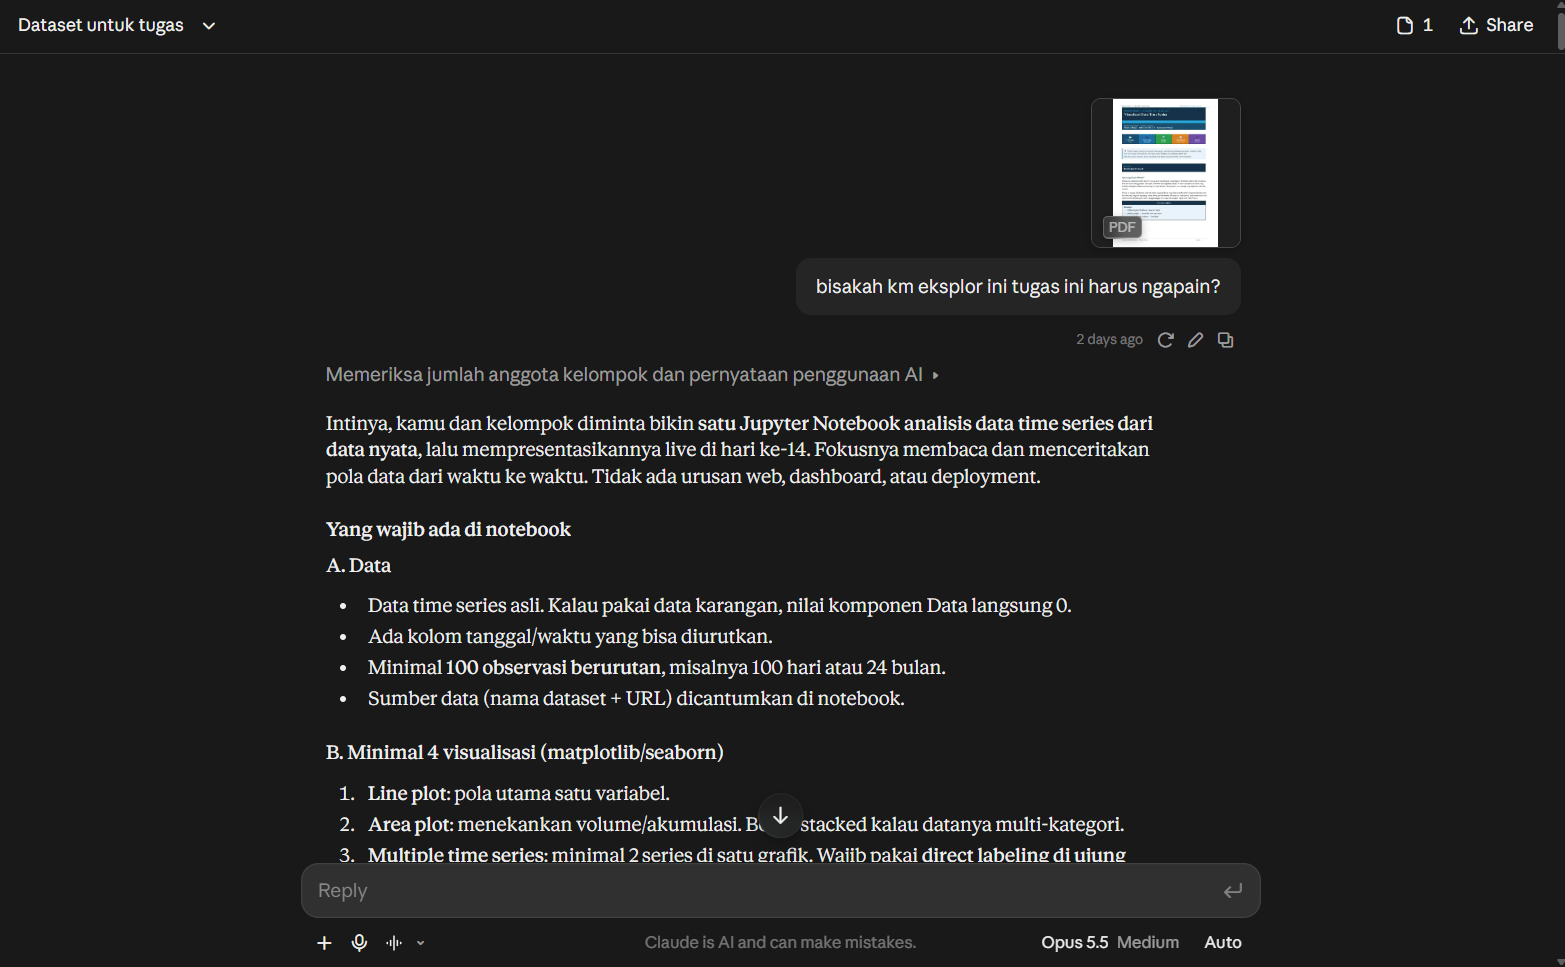

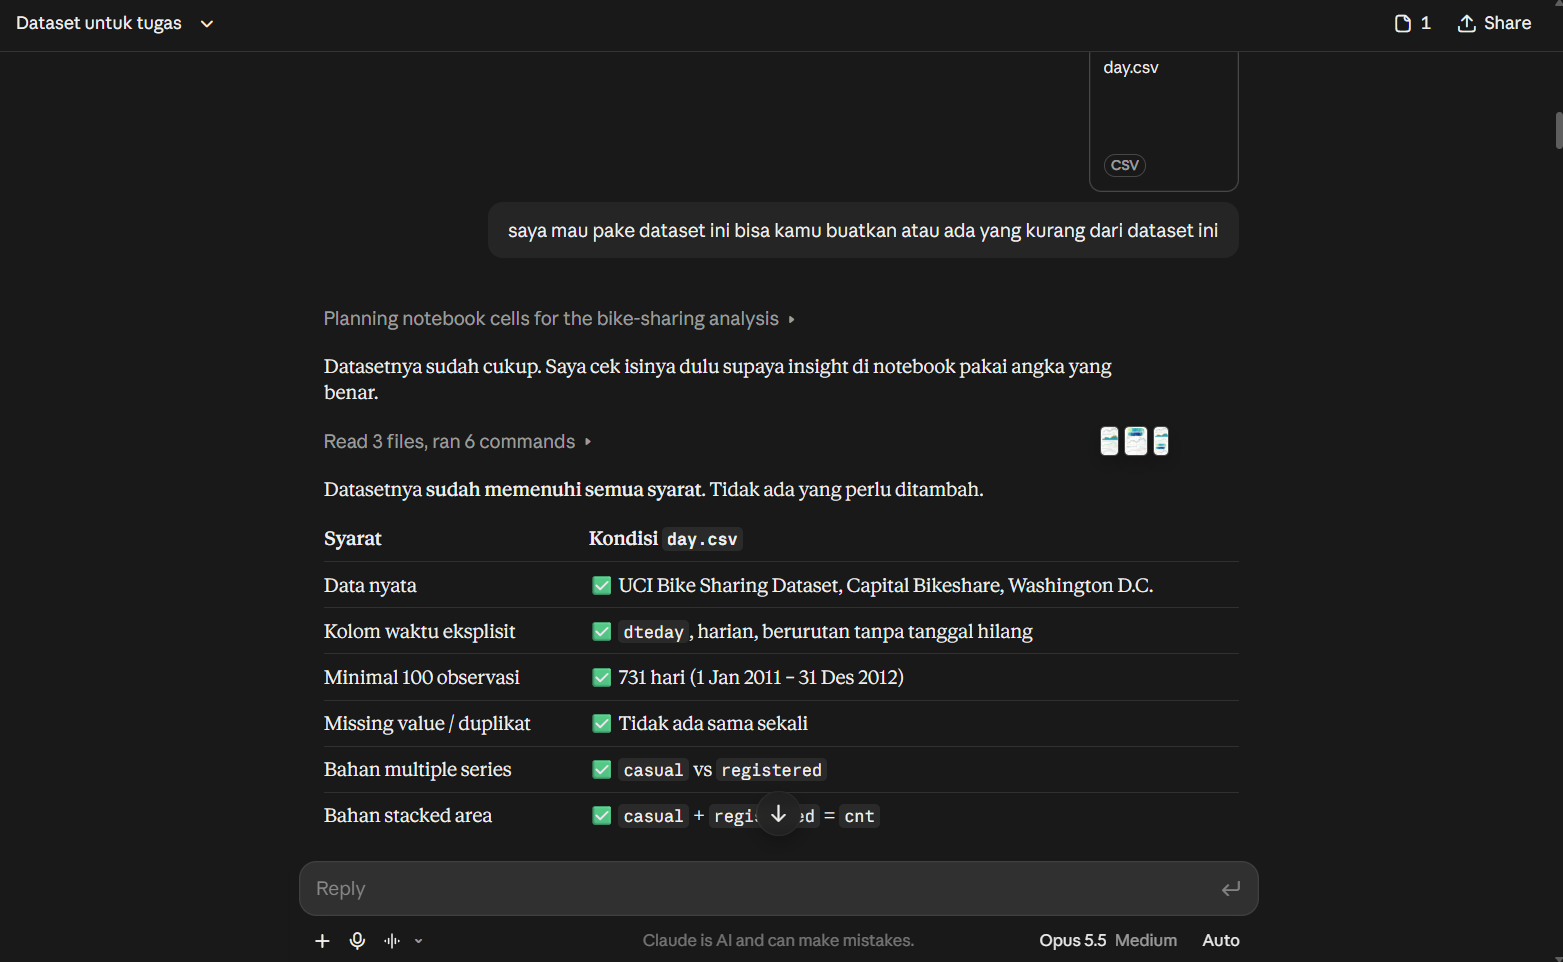

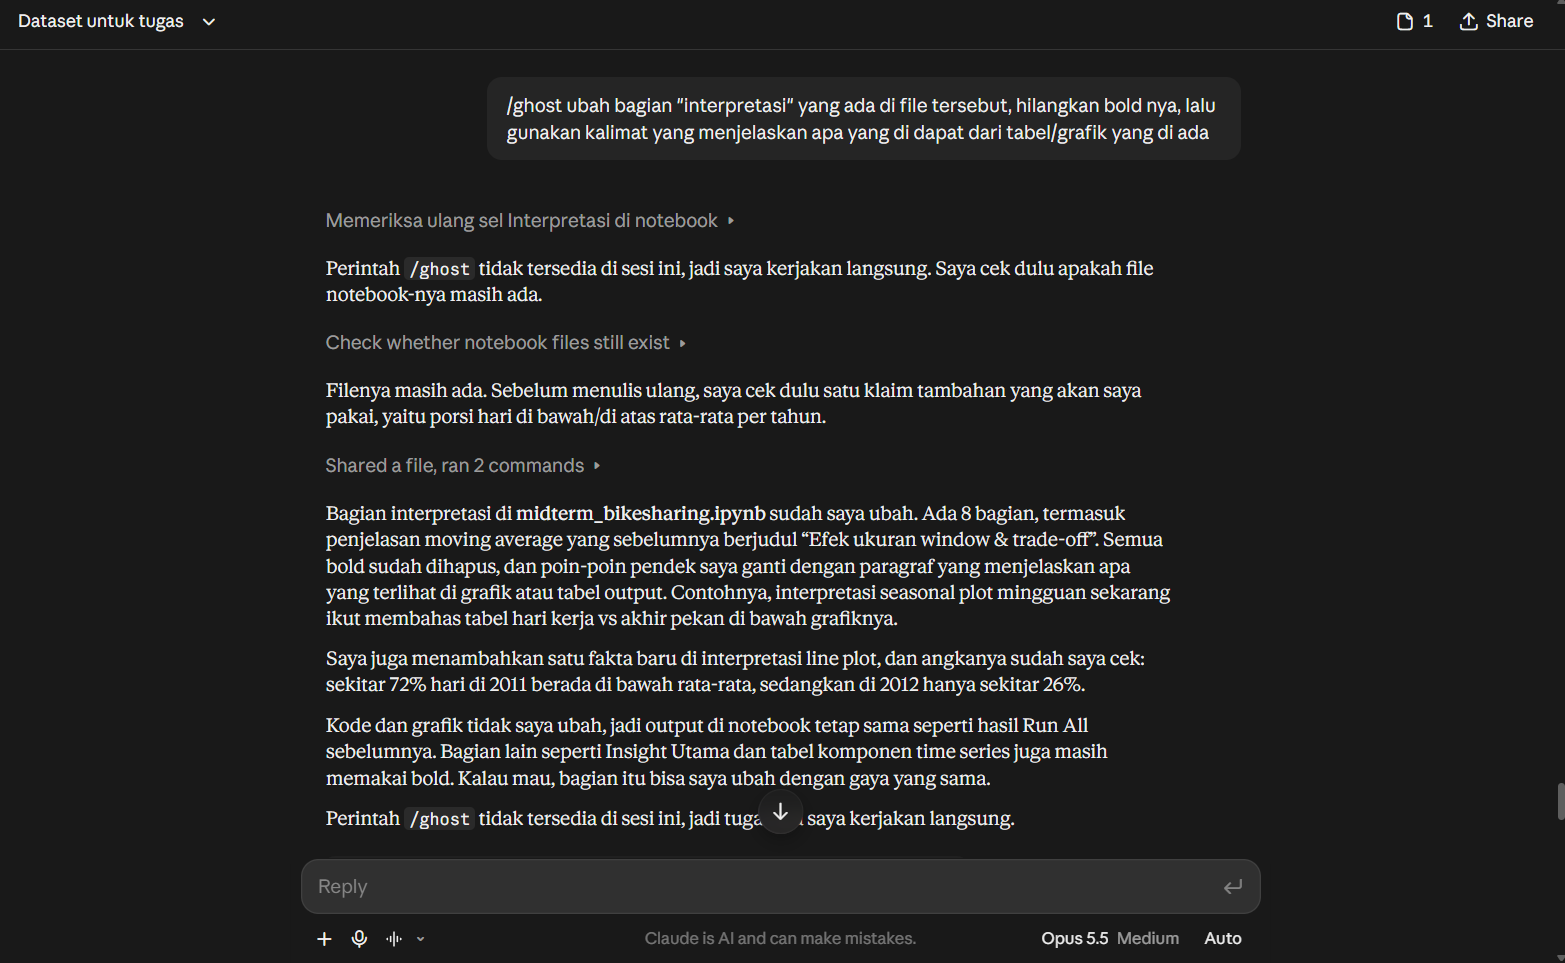